# Harvest Box SQL case study: walkthrough

Every analysis lives in `sql/` as a plain `.sql` file. This notebook runs each query against the SQLite warehouse, shows the result, and visualises it.

**Contents**
1. Setup and building the warehouse
2. Schema overview and profiling of every table
3. Q1–Q2 data quality and the clean view
4. Q3 revenue growth
5. Q4–Q5 cohort and channel retention
6. Q6 LTV vs CAC
7. Q7 RFM segmentation
8. Q8 cancellation reasons
9. Q9 recipe Pareto
10. Q10–Q11 funnel and A/B test
11. Q12 sessionization
12. Q13 spend percentiles
13. Q14 seasonality by region
14. Q15 query optimisation
15. Recommendations for the business

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "../src")
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from harvest.build_db import DB, build
from harvest.run import connect, run_file, optimisation_demo, SQL_DIR
sns.set_theme(style="whitegrid")
if not DB.exists():
    build()
con = connect()

def show(n):
    path = next(SQL_DIR.glob(f"{n:02d}_*.sql"))
    print(path.read_text())
    return run_file(con, path)

## 2. Schema overview and profiling

In [2]:
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con).name
pd.DataFrame({t: {"rows": pd.read_sql(f"SELECT COUNT(*) n FROM {t}", con).n[0],
                  "columns": ", ".join(pd.read_sql(f"SELECT * FROM {t} LIMIT 1", con).columns)} for t in tables}).T

,rows,columns
dim_customers,12000,"customer_id, signup_date, region, acquisition_channel, plan_id, age_band"
dim_plans,4,"plan_id, plan_name, people, recipes_per_box, weekly_price_gbp"
dim_recipes,60,"recipe_id, recipe_name, cuisine, ingredient_cost_gbp, cook_minutes"
fact_cancellations,10422,"customer_id, cancel_date, reason"
fact_events,60326,"session_id, visitor_id, event_time, event_name, device, ab_variant"
fact_marketing,150,"month, channel, spend_gbp"
fact_order_items,423648,"order_id, recipe_id"
fact_orders,124437,"order_id, customer_id, delivery_date, plan_id, status, revenue_gbp, discount_gbp"


In [3]:
customers = pd.read_sql("SELECT * FROM dim_customers", con); customers.info(); customers.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   customer_id          12000 non-null  int64
 1   signup_date          12000 non-null  str  
 2   region               12000 non-null  str  
 3   acquisition_channel  12000 non-null  str  
 4   plan_id              12000 non-null  int64
 5   age_band             12000 non-null  str  
dtypes: int64(2), str(4)
memory usage: 562.6 KB

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,12000.0,NaN,NaN,NaN,6000.5,3464.24595,1.0,3000.75,6000.5,9000.25,12000.0
signup_date,12000,910,2026-01-07,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,12000,8,London,2402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acquisition_channel,12000,5,paid_social,4179,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_id,12000.0,NaN,NaN,NaN,2.10175,1.051422,1.0,1.0,2.0,3.0,4.0
age_band,12000,5,25-34,4090,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
orders = pd.read_sql("SELECT * FROM fact_orders", con); orders.info(); orders.describe(include="all").T

<class 'pandas.DataFrame'>
RangeIndex: 124437 entries, 0 to 124436
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_id       124437 non-null  int64  
 1   customer_id    124437 non-null  int64  
 2   delivery_date  124437 non-null  str    
 3   plan_id        124437 non-null  int64  
 4   status         124437 non-null  str    
 5   revenue_gbp    124429 non-null  float64
 6   discount_gbp   124437 non-null  float64
dtypes: float64(2), int64(3), str(2)
memory usage: 6.6 MB

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,124437.0,NaN,NaN,NaN,66185.32246,628168.995171,1.0,31106.0,62212.0,93319.0,99000004.0
customer_id,124437.0,NaN,NaN,NaN,6073.776096,7186.446589,1.0,3084.0,6028.0,9048.0,999999.0
delivery_date,124437,908,2026-01-14,231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
plan_id,124437.0,NaN,NaN,NaN,2.110345,1.058215,1.0,1.0,2.0,3.0,4.0
status,124437,2,delivered,121394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue_gbp,124429.0,NaN,NaN,NaN,53.353282,13.696278,21.0,41.99,51.99,64.99,79.99
discount_gbp,124437.0,NaN,NaN,NaN,1.469078,4.948488,0.0,0.0,0.0,0.0,39.99


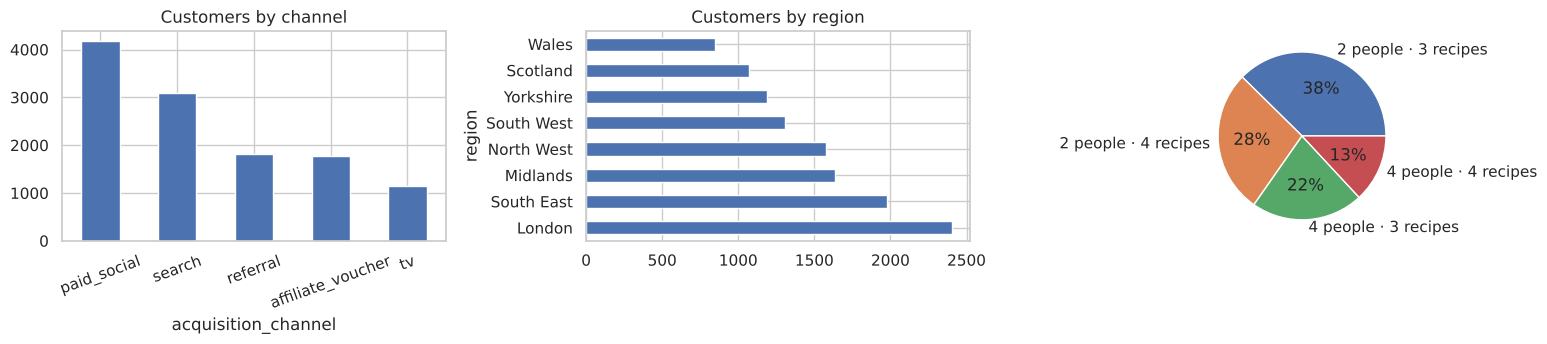

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
customers.acquisition_channel.value_counts().plot.bar(ax=axes[0], rot=20, title="Customers by channel")
customers.region.value_counts().plot.barh(ax=axes[1], title="Customers by region")
pd.read_sql("SELECT p.plan_name, COUNT(*) n FROM dim_customers c JOIN dim_plans p USING(plan_id) GROUP BY 1", con).set_index("plan_name").n.plot.pie(ax=axes[2], autopct="%1.0f%%")
axes[2].set_ylabel(""); plt.tight_layout()

## 3. Data quality

In [6]:
show(1)

-- Q1. Can we trust the data? Run quality checks before any analysis.
-- Techniques: UNION ALL of checks, anti-joins (LEFT JOIN ... IS NULL), GROUP BY ... HAVING for duplicates.

SELECT 'duplicate order rows' AS check_name,
       COUNT(*) AS failing_rows
FROM (
    SELECT order_id
    FROM fact_orders
    GROUP BY order_id
    HAVING COUNT(*) > 1
)
UNION ALL
SELECT 'orders with missing revenue', COUNT(*)
FROM fact_orders
WHERE revenue_gbp IS NULL
UNION ALL
SELECT 'orders for unknown customers', COUNT(*)
FROM fact_orders o
LEFT JOIN dim_customers c ON c.customer_id = o.customer_id
WHERE c.customer_id IS NULL
UNION ALL
SELECT 'order items for unknown recipes', COUNT(*)
FROM fact_order_items i
LEFT JOIN dim_recipes r ON r.recipe_id = i.recipe_id
WHERE r.recipe_id IS NULL
UNION ALL
SELECT 'deliveries before signup', COUNT(*)
FROM fact_orders o
JOIN dim_customers c ON c.customer_id = o.customer_id
WHERE o.delivery_date < c.signup_date
UNION ALL
SELECT 'cancellations before signup', COUNT(*

,check_name,failing_rows
0,duplicate order rows,15
1,orders with missing revenue,8
2,orders for unknown customers,5
3,order items for unknown recipes,0
4,deliveries before signup,0
5,cancellations before signup,0


In [7]:
show(2)

-- Q2. Create a clean, de-duplicated orders view that every later query uses.
-- Techniques: CREATE VIEW, ROW_NUMBER() window for de-duplication, filtering orphans and nulls.

DROP VIEW IF EXISTS v_orders;
CREATE VIEW v_orders AS
WITH ranked AS (
    SELECT o.*,
           ROW_NUMBER() OVER (PARTITION BY o.order_id ORDER BY o.rowid) AS rn
    FROM fact_orders o
    JOIN dim_customers c ON c.customer_id = o.customer_id      -- drop orphans
)
SELECT order_id, customer_id, delivery_date, plan_id, status, revenue_gbp, discount_gbp
FROM ranked
WHERE rn = 1                     -- drop duplicates
  AND revenue_gbp IS NOT NULL    -- drop rows with missing revenue
  AND status = 'delivered';      -- refunds don't count as revenue

SELECT
    (SELECT COUNT(*) FROM fact_orders) AS raw_rows,
    (SELECT COUNT(*) FROM v_orders)    AS clean_delivered_rows,
    (SELECT COUNT(*) FROM fact_orders WHERE status = 'refunded') AS refunded_rows;

,raw_rows,clean_delivered_rows,refunded_rows
0,124437,121369,3043


## 4. Revenue growth

In [8]:
m = show(3); m.tail(12)

-- Q3. How is revenue trending? Month-on-month and year-on-year growth.
-- Techniques: date truncation with strftime, LAG() window function, NULLIF to avoid division by zero.

WITH monthly AS (
    SELECT strftime('%Y-%m', delivery_date) AS month,
           ROUND(SUM(revenue_gbp), 2)        AS revenue_gbp,
           COUNT(DISTINCT customer_id)       AS active_customers,
           COUNT(*)                          AS boxes
    FROM v_orders
    GROUP BY 1
)
SELECT month,
       revenue_gbp,
       active_customers,
       boxes,
       ROUND(revenue_gbp / boxes, 2) AS avg_box_value_gbp,
       ROUND(100.0 * (revenue_gbp - LAG(revenue_gbp, 1) OVER w) / NULLIF(LAG(revenue_gbp, 1) OVER w, 0), 1)  AS mom_growth_pct,
       ROUND(100.0 * (revenue_gbp - LAG(revenue_gbp, 12) OVER w) / NULLIF(LAG(revenue_gbp, 12) OVER w, 0), 1) AS yoy_growth_pct
FROM monthly
WINDOW w AS (ORDER BY month)
ORDER BY month;

,month,revenue_gbp,active_customers,boxes,avg_box_value_gbp,mom_growth_pct,yoy_growth_pct
18,2025-07,221740.59,1577,4082,54.32,-10.7,53.2
19,2025-08,221387.49,1578,4107,53.90,-0.2,47.0
20,2025-09,254300.81,1630,4725,53.82,14.9,44.0
21,2025-10,264207.12,1676,4916,53.74,3.9,41.9
22,2025-11,277652.67,1696,5158,53.83,5.1,38.1
23,2025-12,289330.67,1716,5377,53.81,4.2,32.5
24,2026-01,305358.34,1909,5725,53.34,5.5,26.5
25,2026-02,276594.55,1904,5185,53.35,-9.4,22.8
26,2026-03,310098.05,1934,5819,53.29,12.1,23.3
27,2026-04,301075.16,1905,5602,53.74,-2.9,22.1


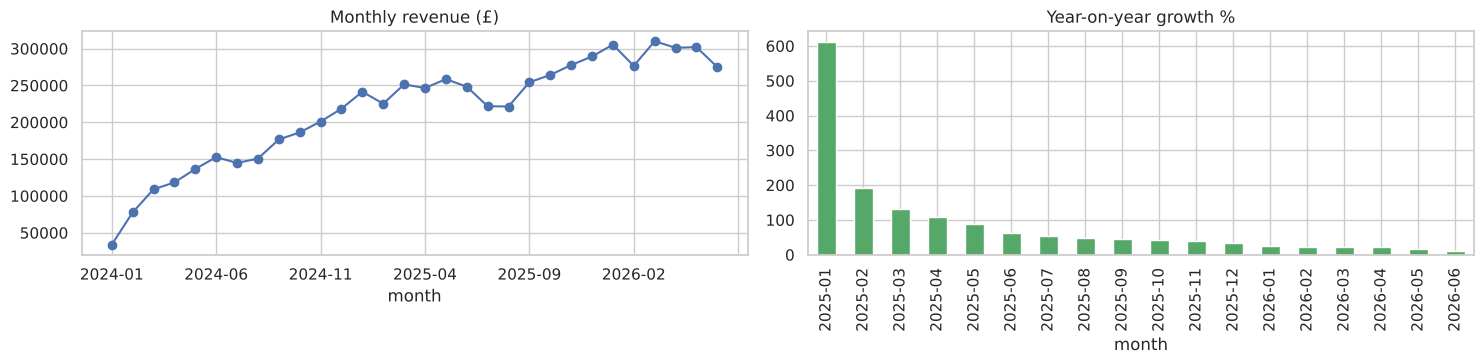

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
m.set_index("month")["revenue_gbp"].plot(ax=ax[0], marker="o", title="Monthly revenue (£)")
m.set_index("month")["yoy_growth_pct"].dropna().plot.bar(ax=ax[1], title="Year-on-year growth %", color="#55a868")
plt.tight_layout()

## 5. Retention

-- Q4. Do customers stick around? Monthly signup-cohort retention.
-- Techniques: cohort assignment, month-difference arithmetic, conditional aggregation, FIRST_VALUE.

WITH first_order AS (
    SELECT customer_id, MIN(delivery_date) AS first_date
    FROM v_orders
    GROUP BY customer_id
),
activity AS (
    SELECT DISTINCT
           o.customer_id,
           strftime('%Y-%m', f.first_date) AS cohort,
           (CAST(strftime('%Y', o.delivery_date) AS INT) - CAST(strftime('%Y', f.first_date) AS INT)) * 12
         + (CAST(strftime('%m', o.delivery_date) AS INT) - CAST(strftime('%m', f.first_date) AS INT)) AS month_number
    FROM v_orders o
    JOIN first_order f USING (customer_id)
),
cohort_counts AS (
    SELECT cohort, month_number, COUNT(*) AS customers
    FROM activity
    GROUP BY cohort, month_number
)
SELECT cohort,
       month_number,
       customers,
       ROUND(100.0 * customers / FIRST_VALUE(customers) OVER (PARTITION BY cohort ORDER BY month_number), 1) AS retenti

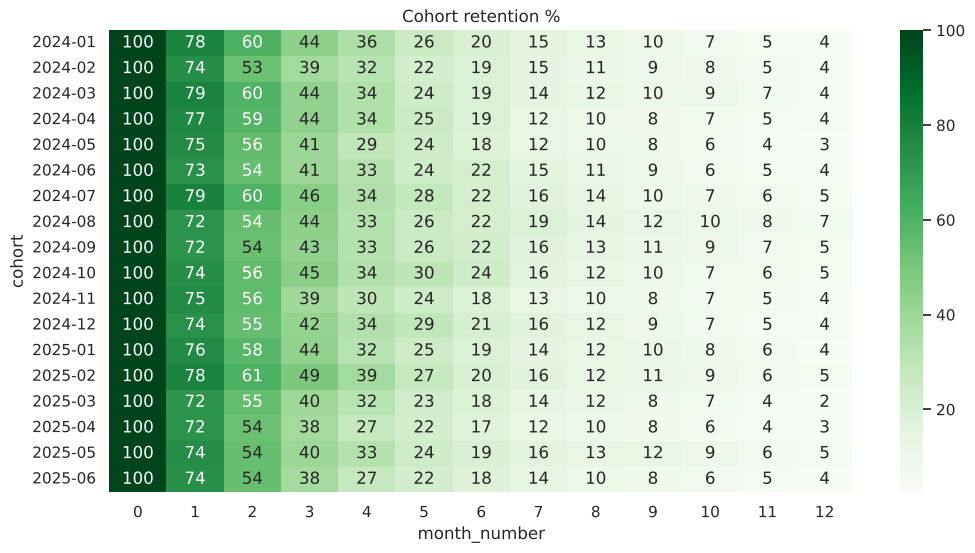

In [10]:
c = show(4)
heat = c.pivot(index="cohort", columns="month_number", values="retention_pct").loc[:"2025-06"]
plt.figure(figsize=(12, 6)); sns.heatmap(heat, annot=True, fmt=".0f", cmap="Greens"); plt.title("Cohort retention %");

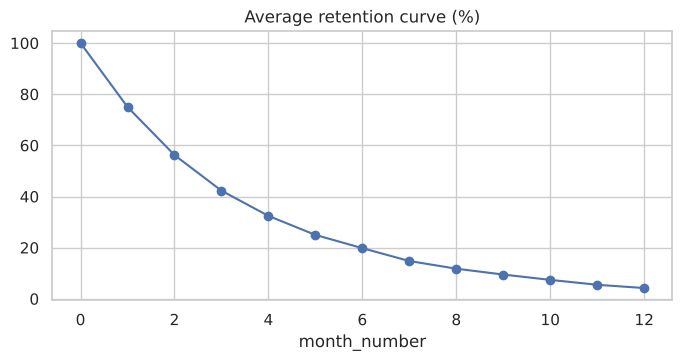

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
avg retention %,100.0,75.0,56.2,42.3,32.4,25.0,19.8,14.8,11.8,9.5,7.4,5.5,4.2


In [11]:
avg = heat.mean()
avg.plot(marker="o", figsize=(8, 3.5), title="Average retention curve (%)"); avg.round(1).to_frame("avg retention %").T

In [12]:
ch = show(5); ch

-- Q5. Which acquisition channels bring customers who stay? Month-3 and month-6 retention by channel.
-- Techniques: CTE reuse, conditional aggregation with FILTER, only counting cohorts old enough to be measured.

WITH first_order AS (
    SELECT customer_id, MIN(delivery_date) AS first_date
    FROM v_orders
    GROUP BY customer_id
),
activity AS (
    SELECT DISTINCT o.customer_id,
           (julianday(o.delivery_date) - julianday(f.first_date)) / 30.44 AS months_since_first
    FROM v_orders o
    JOIN first_order f USING (customer_id)
),
per_customer AS (
    SELECT f.customer_id,
           c.acquisition_channel,
           f.first_date,
           MAX(a.months_since_first >= 3 AND a.months_since_first < 4) AS active_m3,
           MAX(a.months_since_first >= 6 AND a.months_since_first < 7) AS active_m6
    FROM first_order f
    JOIN dim_customers c USING (customer_id)
    JOIN activity a USING (customer_id)
    GROUP BY f.customer_id
)
SELECT acquisition_channel,
       COUNT

,acquisition_channel,customers,retained_month_3_pct,retained_month_6_pct
0,referral,1766,53.4,31.3
1,search,3000,40.7,19.5
2,tv,1105,34.8,15.6
3,paid_social,4050,33.0,13.0
4,affiliate_voucher,1702,17.5,4.0


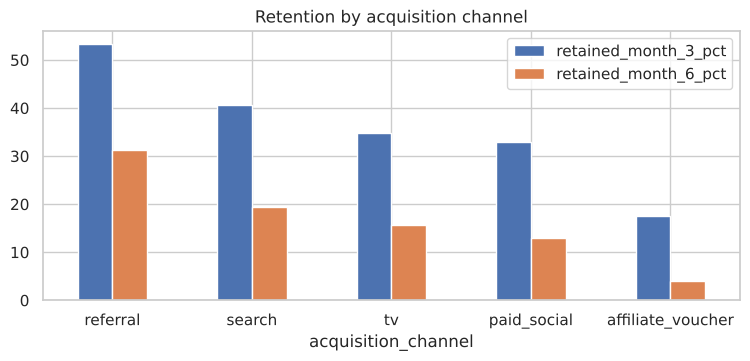

In [13]:
ch.set_index('acquisition_channel')[['retained_month_3_pct', 'retained_month_6_pct']].plot.bar(figsize=(9, 3.5), rot=0, title='Retention by acquisition channel');

## 6. LTV vs CAC

In [14]:
l = show(6); l

-- Q6. Is each channel profitable? Customer lifetime value (gross margin) vs acquisition cost.
-- Techniques: joining facts at different grains (orders, items, marketing) via separate aggregates first.

WITH box_cost AS (
    SELECT i.order_id, SUM(r.ingredient_cost_gbp * p.people) AS ingredients_gbp
    FROM fact_order_items i
    JOIN dim_recipes r USING (recipe_id)
    JOIN v_orders o USING (order_id)
    JOIN dim_plans p ON p.plan_id = o.plan_id
    GROUP BY i.order_id
),
customer_value AS (
    SELECT c.acquisition_channel,
           o.customer_id,
           SUM(o.revenue_gbp)                                   AS revenue_gbp,
           SUM(o.revenue_gbp - b.ingredients_gbp - 6.50)        AS gross_margin_gbp   -- £6.50 packaging + delivery per box
    FROM v_orders o
    JOIN box_cost b USING (order_id)
    JOIN dim_customers c USING (customer_id)
    GROUP BY c.acquisition_channel, o.customer_id
),
spend AS (
    SELECT channel AS acquisition_channel, SUM(spend_gbp) AS spend_gb

,acquisition_channel,customers,revenue_per_customer_gbp,margin_per_customer_gbp,cac_gbp,ltv_to_cac
0,referral,1812,815.36,178.54,15.20,11.74
1,search,3095,610.88,132.50,42.58,3.11
2,paid_social,4179,513.77,107.78,47.85,2.25
3,affiliate_voucher,1778,312.95,52.22,29.81,1.75
4,tv,1136,533.59,115.03,68.94,1.67


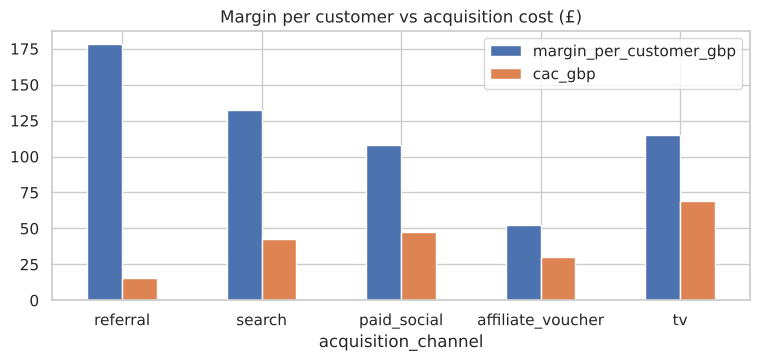

In [15]:
ax = l.set_index("acquisition_channel")[["margin_per_customer_gbp", "cac_gbp"]].plot.bar(figsize=(9, 3.5), rot=0, title="Margin per customer vs acquisition cost (£)")

## 7. RFM segmentation

In [16]:
r = show(7); r

-- Q7. Who are our best customers? RFM (recency, frequency, monetary) segmentation.
-- Techniques: NTILE() quintiles, CASE-based segment rules, julianday date arithmetic.

WITH base AS (
    SELECT customer_id,
           julianday('2026-06-29') - julianday(MAX(delivery_date)) AS recency_days,
           COUNT(*)                                               AS frequency,
           SUM(revenue_gbp)                                       AS monetary_gbp
    FROM v_orders
    GROUP BY customer_id
),
scored AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,   -- 5 = most recent
           NTILE(5) OVER (ORDER BY frequency)          AS f_score,
           NTILE(5) OVER (ORDER BY monetary_gbp)       AS m_score
    FROM base
),
segmented AS (
    SELECT *,
           CASE
               WHEN r_score >= 4 AND f_score >= 4 THEN 'Champions'
               WHEN r_score >= 3 AND f_score >= 3 THEN 'Loyal'
               WHEN r_score >= 4 AND f_score <= 2 THEN 'New

,segment,customers,pct_customers,revenue_gbp,pct_revenue,avg_days_since_last_box,avg_boxes
0,Champions,2117,18.2,2506174.0,38.7,69.0,21.7
1,Loyal,2336,20.1,1624948.0,25.1,217.0,12.9
2,At risk,1374,11.8,1144557.0,17.7,487.0,15.7
3,Lost high-value,1146,9.9,716378.0,11.1,709.0,11.7
4,Low engagement,3022,26.0,308028.0,4.8,533.0,2.2
5,New / promising,1628,14.0,175509.0,2.7,81.0,2.3


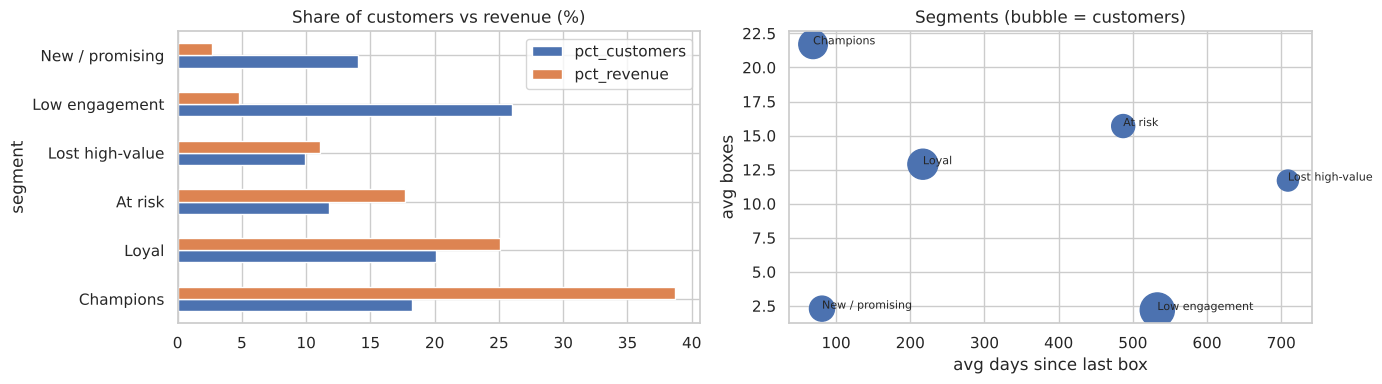

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r.set_index("segment")[["pct_customers", "pct_revenue"]].plot.barh(ax=axes[0], title="Share of customers vs revenue (%)")
axes[1].scatter(r.avg_days_since_last_box, r.avg_boxes, s=r.customers / 5)
for _, x in r.iterrows(): axes[1].annotate(x.segment, (x.avg_days_since_last_box, x.avg_boxes), fontsize=8)
axes[1].set(xlabel="avg days since last box", ylabel="avg boxes", title="Segments (bubble = customers)"); plt.tight_layout()

## 8. Cancellation reasons

-- Q8. Why do customers cancel, and does it differ for early vs established customers?
-- Techniques: tenure bucketing with CASE, percentage of total within group via window SUM() OVER (PARTITION BY).

WITH tenure AS (
    SELECT x.customer_id,
           x.reason,
           COUNT(o.order_id) AS boxes_received
    FROM fact_cancellations x
    LEFT JOIN v_orders o ON o.customer_id = x.customer_id AND o.delivery_date <= x.cancel_date
    GROUP BY x.customer_id, x.reason
),
bucketed AS (
    SELECT CASE WHEN boxes_received <= 2 THEN '1. trialists (≤2 boxes)'
                WHEN boxes_received <= 8 THEN '2. early (3–8 boxes)'
                ELSE '3. established (9+ boxes)' END AS tenure_group,
           reason
    FROM tenure
)
SELECT tenure_group,
       reason,
       COUNT(*) AS cancellations,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY tenure_group), 1) AS pct_of_group
FROM bucketed
GROUP BY tenure_group, reason
ORDER BY tenure_group, cancellations DESC;

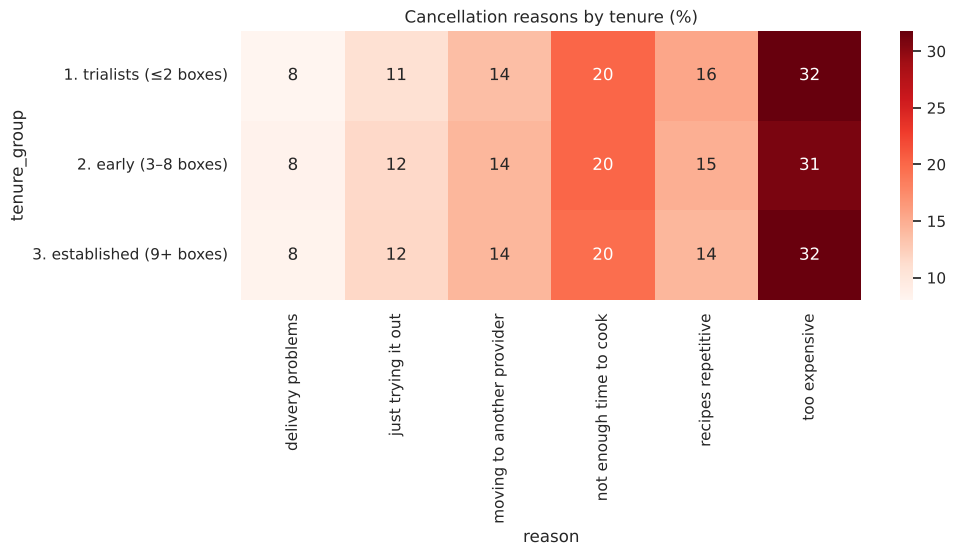

In [18]:
x = show(8)
plt.figure(figsize=(10, 3.5)); sns.heatmap(x.pivot(index="tenure_group", columns="reason", values="pct_of_group"), annot=True, fmt=".0f", cmap="Reds")
plt.title("Cancellation reasons by tenure (%)");

## 9. Recipe Pareto

In [19]:
p = show(9); p.head(12)

-- Q9. Do a few recipes drive most demand? Pareto (80/20) analysis.
-- Techniques: running total with SUM() OVER (ORDER BY ... ROWS UNBOUNDED PRECEDING), RANK().

WITH demand AS (
    SELECT r.recipe_id, r.recipe_name, r.cuisine, COUNT(*) AS times_ordered
    FROM fact_order_items i
    JOIN v_orders o USING (order_id)
    JOIN dim_recipes r USING (recipe_id)
    GROUP BY r.recipe_id
)
SELECT RANK() OVER (ORDER BY times_ordered DESC) AS rank,
       recipe_name,
       cuisine,
       times_ordered,
       ROUND(100.0 * times_ordered / SUM(times_ordered) OVER (), 2) AS share_pct,
       ROUND(100.0 * SUM(times_ordered) OVER (ORDER BY times_ordered DESC ROWS UNBOUNDED PRECEDING)
                   / SUM(times_ordered) OVER (), 1) AS cumulative_share_pct
FROM demand
ORDER BY times_ordered DESC;

,rank,recipe_name,cuisine,times_ordered,share_pct,cumulative_share_pct
0,1,Mediterranean recipe 3,Mediterranean,31685,7.67,7.7
1,2,Asian recipe 2,Asian,29838,7.22,14.9
2,3,British recipe 9,British,27453,6.64,21.5
3,4,Indian recipe 4,Indian,23014,5.57,27.1
4,5,Vegan recipe 1,Vegan,22744,5.50,32.6
5,6,British recipe 5,British,17660,4.27,36.9
6,7,Asian recipe 3,Asian,15426,3.73,40.6
7,8,Mediterranean recipe 4,Mediterranean,13797,3.34,43.9
8,9,Mexican recipe 2,Mexican,13304,3.22,47.2
9,10,Mediterranean recipe 5,Mediterranean,12088,2.93,50.1


Recipes needed for 80% of demand: 27 of 60

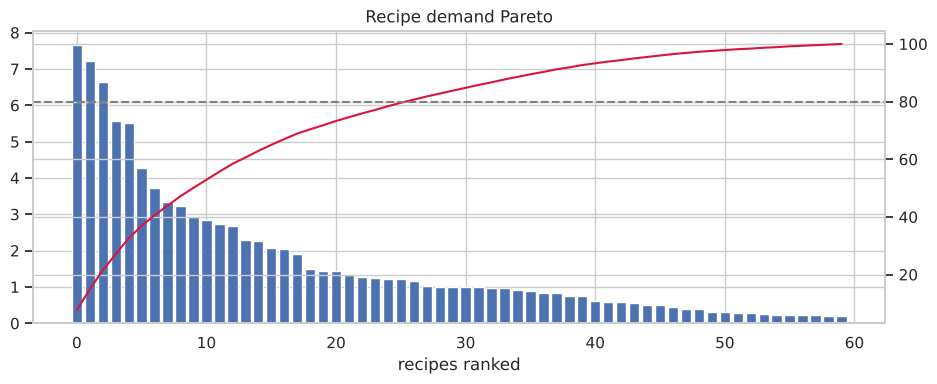

In [20]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(range(len(p)), p.share_pct); ax2 = ax.twinx(); ax2.plot(range(len(p)), p.cumulative_share_pct, c="crimson"); ax2.axhline(80, ls="--", c="grey")
ax.set(title="Recipe demand Pareto", xlabel="recipes ranked"); print("Recipes needed for 80% of demand:", (p.cumulative_share_pct < 80).sum() + 1, "of", len(p))

## 10. Funnel and A/B test

In [21]:
f = show(10); f

-- Q10. Where do visitors drop out of the sign-up funnel, by device?
-- Techniques: pivoting events to one row per session with MAX(CASE ...), step-to-step conversion.

WITH sessions AS (
    SELECT session_id,
           device,
           MAX(event_name = 'landing')     AS landing,
           MAX(event_name = 'menu')        AS menu,
           MAX(event_name = 'plan_select') AS plan_select,
           MAX(event_name = 'checkout')    AS checkout,
           MAX(event_name = 'purchase')    AS purchase
    FROM fact_events
    GROUP BY session_id, device
)
SELECT device,
       SUM(landing) AS sessions,
       ROUND(100.0 * SUM(menu)        / SUM(landing), 1)     AS landing_to_menu_pct,
       ROUND(100.0 * SUM(plan_select) / SUM(menu), 1)        AS menu_to_plan_pct,
       ROUND(100.0 * SUM(checkout)    / SUM(plan_select), 1) AS plan_to_checkout_pct,
       ROUND(100.0 * SUM(purchase)    / SUM(checkout), 1)    AS checkout_to_purchase_pct,
       ROUND(100.0 * SUM(purchase)    / SUM(lan

,device,sessions,landing_to_menu_pct,menu_to_plan_pct,plan_to_checkout_pct,checkout_to_purchase_pct,overall_conversion_pct
0,mobile,16106,61.9,54.6,48.1,56.4,9.17
1,desktop,8099,69.7,62.0,56.1,63.2,15.31
2,tablet,1795,67.6,58.6,49.9,54.6,10.81


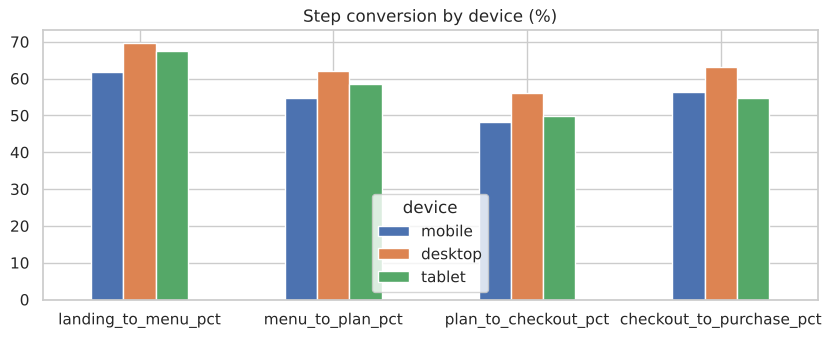

In [22]:
steps = ["landing_to_menu_pct", "menu_to_plan_pct", "plan_to_checkout_pct", "checkout_to_purchase_pct"]
f.set_index("device")[steps].T.plot.bar(figsize=(10, 3.5), rot=0, title="Step conversion by device (%)");

In [23]:
show(11)

-- Q11. Did the new one-page checkout (variant B) increase purchases? A two-proportion z-test in SQL.
-- Techniques: conditional aggregation, cross join of summary rows, sqrt() for the pooled standard error.
-- Metric: purchases / sessions that reached checkout (the step the variant changed).

WITH reached AS (
    SELECT session_id,
           MAX(ab_variant)                AS variant,
           MAX(event_name = 'checkout')   AS saw_checkout,
           MAX(event_name = 'purchase')   AS purchased
    FROM fact_events
    GROUP BY session_id
),
by_variant AS (
    SELECT variant,
           SUM(saw_checkout)                       AS n,
           SUM(purchased)                          AS conversions,
           1.0 * SUM(purchased) / SUM(saw_checkout) AS rate
    FROM reached
    WHERE saw_checkout = 1
    GROUP BY variant
),
test AS (
    SELECT a.n AS n_a, a.rate AS rate_a, b.n AS n_b, b.rate AS rate_b,
           (a.conversions + b.conversions) * 1.0 / (a.n + b.n) AS pooled
    FR

,n_a,conversion_a_pct,n_b,conversion_b_pct,relative_lift_pct,z_score,verdict
0,2455,56.46,2484,61.39,8.7,3.53,significant at 5%


## 11. Sessionization (gaps and islands)

In [24]:
show(12)

-- Q12. Rebuild sessions from raw events: a "gaps and islands" problem.
-- A new session starts when a visitor is inactive for more than 30 minutes.
-- Techniques: LAG() to find gaps, running SUM() of "new session" flags to number the islands.

WITH ordered AS (
    SELECT visitor_id, event_time, event_name,
           (julianday(event_time) - julianday(LAG(event_time) OVER (PARTITION BY visitor_id ORDER BY event_time))) * 24 * 60
               AS minutes_since_prev
    FROM fact_events
),
flagged AS (
    SELECT *,
           CASE WHEN minutes_since_prev IS NULL OR minutes_since_prev > 30 THEN 1 ELSE 0 END AS new_session
    FROM ordered
),
numbered AS (
    SELECT *,
           SUM(new_session) OVER (PARTITION BY visitor_id ORDER BY event_time ROWS UNBOUNDED PRECEDING) AS session_no
    FROM flagged
),
sessions AS (
    SELECT visitor_id, session_no,
           MIN(event_time) AS started, MAX(event_time) AS ended, COUNT(*) AS events,
           MAX(event_name = 'purchase') AS purcha

,reconstructed_sessions,logged_sessions,avg_events_per_session,avg_minutes,purchase_rate_pct
0,25988,26000,2.32,4.6,11.2


## 12. Spend percentiles

-- Q13. What does a typical customer spend? Spend percentiles without a PERCENTILE function.
-- Techniques: PERCENT_RANK() / CUME_DIST() windows, picking the first row past each percentile.

WITH spend AS (
    SELECT customer_id, SUM(revenue_gbp) AS total_spend_gbp
    FROM v_orders
    GROUP BY customer_id
),
ranked AS (
    SELECT total_spend_gbp, CUME_DIST() OVER (ORDER BY total_spend_gbp) AS cd
    FROM spend
)
SELECT p.percentile,
       (SELECT ROUND(MIN(total_spend_gbp), 2) FROM ranked WHERE cd >= p.percentile / 100.0) AS spend_gbp
FROM (SELECT 10 AS percentile UNION ALL SELECT 25 UNION ALL SELECT 50 UNION ALL SELECT 75
      UNION ALL SELECT 90 UNION ALL SELECT 99) p
ORDER BY p.percentile;

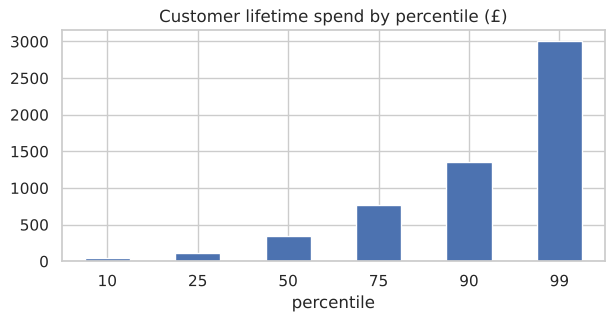

,percentile,spend_gbp
0,10,41.99
1,25,115.47
2,50,350.93
3,75,763.63
4,90,1348.54
5,99,3002.42


In [25]:
pc = show(13); pc.set_index("percentile").spend_gbp.plot.bar(figsize=(7, 3), rot=0, title="Customer lifetime spend by percentile (£)"); pc

## 13. Seasonality by region

-- Q14. Is there a winter peak, and does it differ by region? Seasonal index per region.
-- Techniques: averages of averages, ratio to the region's own mean, AVG() OVER (PARTITION BY).

WITH weekly AS (
    SELECT c.region, o.delivery_date, COUNT(*) AS boxes
    FROM v_orders o
    JOIN dim_customers c USING (customer_id)
    WHERE o.delivery_date >= '2025-01-01' AND o.delivery_date < '2026-01-01'
    GROUP BY c.region, o.delivery_date
),
monthly AS (
    SELECT region, CAST(strftime('%m', delivery_date) AS INT) AS month, AVG(boxes) AS avg_weekly_boxes
    FROM weekly
    GROUP BY region, month
)
SELECT region, month,
       ROUND(avg_weekly_boxes, 1) AS avg_weekly_boxes,
       ROUND(avg_weekly_boxes / AVG(avg_weekly_boxes) OVER (PARTITION BY region), 3) AS seasonal_index
FROM monthly
ORDER BY region, month;

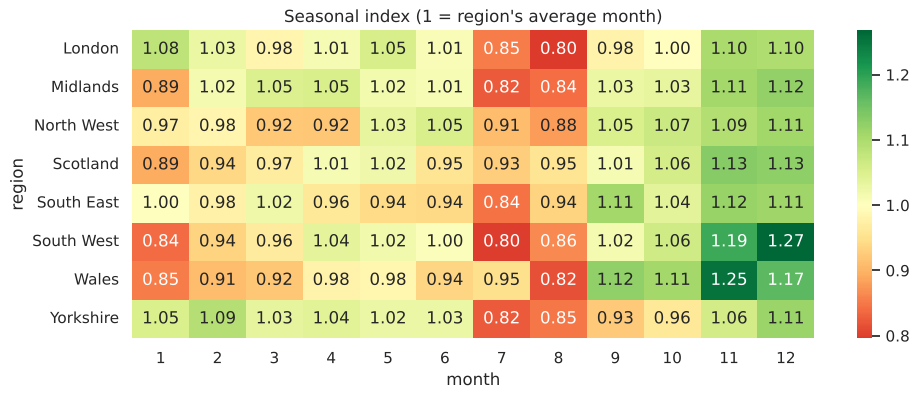

In [26]:
s = show(14)
plt.figure(figsize=(11, 4)); sns.heatmap(s.pivot(index="region", columns="month", values="seasonal_index"), annot=True, fmt=".2f", cmap="RdYlGn", center=1)
plt.title("Seasonal index (1 = region's average month)");

## 14. Query optimisation

In [27]:
optimisation_demo(con, SQL_DIR / '15_query_optimisation.sql')

,version,query_plan,avg_ms
0,without index,SCAN fact_orders | USE TEMP B-TREE FOR GROUP BY,6.34
1,with index,SEARCH fact_orders USING COVERING INDEX idx_orders_customer_date (customer_id>? AND customer_id<?),1.15


## 15. Recommendations
1. **Fix the pipeline:** de-duplicate orders and enforce foreign keys at ingestion.
2. **Shift acquisition budget to referrals** (LTV:CAC ≈ 12) and review TV and voucher spend (below 2).
3. **Target the "At risk" RFM segment** before they lapse.
4. **Launch a budget / quick-cook plan:** price and time are the top cancellation reasons.
5. **Roll out the one-page checkout (variant B)** after its significant +8.7% lift, and prioritise mobile funnel UX.
6. **Plan summer pauses** into capacity forecasts.